In [ ]:
from pathlib import Path
import os
import io
import re
import json
import hashlib
import importlib.util
import numpy as np

PROJECT = Path(r"C:\codex\v1.0")
WORK = PROJECT / "data" / "velocity_robustness_20261029"
STYLE_FILE = WORK / "setup_plot_reference.py"
OUTPUT = Path(os.environ.get(
    "VELOCITY_NOTEBOOK_OUTPUT",
    str(PROJECT / "figures" / "velocity_robustness_20261029" / "notebook_output"),
))
OUT = OUTPUT

SEED = 20261029
RESAMPLES = 50_000
FIG_WIDTH_CM, FIG_HEIGHT_CM = 17.9, 11.5
SPECTRUM_YLIM = (1e-5, 1e1)

SPINE_WIDTH = 0.5
MAJOR_TICK_LENGTH = 3
MINOR_TICK_LENGTH = 1.5
TICK_WIDTH = 0.5
X_TICK_PAD, Y_TICK_PAD = 1.5, 1
INDIVIDUAL_LINE_WIDTH = 0.4
INDIVIDUAL_ALPHA = 0.50
MEAN_LINE_WIDTH = 0.9

OUTPUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(OUTPUT / ".mplconfig"))
tex_bin = Path(r"C:\texlive\2025\bin\windows")
if tex_bin.is_dir():
    os.environ["PATH"] = str(tex_bin) + os.pathsep + os.environ.get("PATH", "")

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import LogLocator, NullFormatter
from IPython.display import display

In [2]:
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def read_report(path):
    parts = re.split(r"(?m)^\[([^\r\n]+)\][ \t]*\r?$", path.read_text(encoding="utf-8-sig"))
    meta = fits = data = None
    for title, body in zip(parts[1::2], parts[2::2]):
        if title == "REALIZATION":
            meta = json.JSONDecoder().raw_decode(body.lstrip())[0]
        elif title == "REFERENCE_FITS":
            fits = json.JSONDecoder().raw_decode(body.lstrip())[0]
        elif title == "REFERENCE_SPECTRA":
            data = np.loadtxt(io.StringIO(body.strip()), skiprows=1)
    assert meta is not None and fits is not None and data is not None
    return meta, fits, data[:, :2]


def fit_slope(k, energy, lower, upper):
    good = (k >= lower) & (k <= upper) & np.isfinite(energy) & (energy > 0)
    assert good.sum() >= 3
    x, y = np.log(k[good]), np.log(energy[good])
    slope, intercept = np.polyfit(x, y, 1)
    residual = y - (intercept + slope*x)
    r2 = 1 - np.sum(residual**2) / np.sum((y-y.mean())**2)
    return float(slope), float(intercept), float(r2), int(good.sum())


In [3]:
OUTPUT.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)
# Each row describes resampling ten WHOLE independent realizations.
# The same row is used at every k, preserving within-spectrum dependence.
draws = rng.integers(0, 10, size=(RESAMPLES, 10))
counts = np.zeros((RESAMPLES, 10), dtype=np.uint8)
for j in range(10):
    counts[:, j] = np.count_nonzero(draws == j, axis=1)
assert np.all(counts.sum(axis=1) == 10)
np.save(OUTPUT / "bootstrap_seed_counts.npy", counts)
weights = counts.astype(float) / 10
arrays, summaries, sources = {}, [], []
for n in (21, 24, 27, 30):
    N = 2**(n//3)
    if n in (21, 24):
        root = PROJECT / "data" / "decoding_validation_20261028" / f"n{n}"
        paths = sorted(root.glob("run*/data/3D/decoding_diagnostics.txt"))
    else:
        root = PROJECT / "data" / f"n={n//3}_run10times"
        paths = sorted(root.glob("run*/data/3D/decoding_diagnostics.txt"))
    assert len(paths) == 10, (n, len(paths))
    spectra, fits, seeds = [], [], []
    for index, path in enumerate(paths):
        meta, recorded, data = read_report(path)
        assert meta["n_qubits"] == n
        assert meta["phase_seeds"] == [2025+2*index, 2026+2*index]
        assert meta["velocity_fit_interval"] == [15, N/2]
        assert meta["prescribed_P0"] == .1
        assert meta["parameters"]["k_cutoff"] == 15
        assert meta["parameters"]["component_ratio"] == {21:.08,24:.02,27:.006,30:.002}[n]
        assert data.shape == (N+1, 2)
        assert np.array_equal(data[:,0], np.arange(N+1))
        assert np.isfinite(data).all() and (data[:,1] >= 0).all()
        k, energy = data.T
        fitted = fit_slope(k, energy, 15, N/2)
        assert abs(fitted[0]-recorded["velocity"]["slope"]) < 5e-10
        # Existing raw CSV files provide an independent normalization check.
        csv_path = path.parent / f"turb_Ek_nq={n}.csv"
        csv_check = None
        if csv_path.exists():
            direct = np.loadtxt(csv_path, delimiter=",", skiprows=1)
            assert direct.shape == (N,2)
            assert np.array_equal(direct[:,0], k[1:])
            assert np.allclose(direct[:,1], energy[1:], rtol=1e-10, atol=0)
            csv_check = {"path": str(csv_path), "sha256": sha256(csv_path)}
        sources.append({"n":n, "seeds":meta["phase_seeds"], "path":str(path),
                        "sha256":sha256(path), "raw_csv_check":csv_check})
        spectra.append(energy)
        fits.append(fitted)
        seeds.append(meta["phase_seeds"])
    spectra = np.array(spectra)
    fits = np.array(fits)
    mean = spectra.mean(axis=0)
    ci = np.empty((2, len(k)))
    for start in range(0, len(k), 128):
        end = min(start+128, len(k))
        resampled_means = weights @ spectra[:, start:end]
        ci[:, start:end] = np.quantile(resampled_means, [.025,.975], axis=0)
    slopes = fits[:,0]
    bootstrap_slopes = weights @ slopes
    slope_ci = np.quantile(bootstrap_slopes, [.025,.975])
    # Independent direct-index check of the bootstrap count formulation.
    assert np.allclose(bootstrap_slopes[:100], slopes[draws[:100]].mean(axis=1), atol=1e-14)
    assert np.allclose((weights @ spectra[:,[15, N//2]])[:100],
                       spectra[draws[:100]][:,:,[15,N//2]].mean(axis=1), atol=1e-13)
    item = {"n":n,"N":N,"number_of_realizations":10,"phase_seeds":seeds,
            "component_population":meta["parameters"]["component_ratio"],
            "fit_interval":[15,N//2],"fitting_shells":int(fits[0,3]),
            "mean_slope":float(slopes.mean()),"slope_sample_sd":float(slopes.std(ddof=1)),
            "slope_mean_ci95":[float(x) for x in slope_ci],
            "individual_slopes":slopes.tolist(), "individual_r_squared":fits[:,2].tolist(),
            "mean_r_squared":float(fits[:,2].mean()),
            "slope_of_mean_spectrum":fit_slope(k, mean, 15, N/2)[0],
            "mean_slope_minus_minus_five_thirds":float(slopes.mean()+5/3),
            "minus_five_thirds_in_ci":bool(slope_ci[0] <= -5/3 <= slope_ci[1]),
            "positive_spectrum_min":float(spectra[:,1:][spectra[:,1:]>0].min()),
            "spectrum_max":float(spectra[:,1:].max())}
    summaries.append(item)
    arrays[f"n{n}_k"] = k
    arrays[f"n{n}_spectra"] = spectra
    arrays[f"n{n}_mean"] = mean
    arrays[f"n{n}_ci95"] = ci
    arrays[f"n{n}_slopes"] = slopes
    arrays[f"n{n}_fits"] = fits
    print(f"n={n}: mean slope={item['mean_slope']:.8f}, "
      f"95% CI={item['slope_mean_ci95']}")
np.savez_compressed(OUTPUT / "velocity_ensemble_data.npz", **arrays)
result = {
    "bootstrap_resamples":RESAMPLES,"bootstrap_seed":SEED,
    "bootstrap_type":"nonparametric percentile bootstrap of the arithmetic ensemble mean",
    "resampling_unit":"whole phase realization (10 realizations per grid)",
    "confidence_level":.95,"spectrum_bands":"pointwise, not simultaneous",
    "slope_statistic":"arithmetic mean of ten per-realization ordinary-least-squares log-log slopes",
    "fit_weighting":"equal weight per integer wavenumber shell; no smoothing or shell weighting",
    "spectrum_definition":"E(k)=0.5 sum_shell sum_components |FFT(u_component)/N^3|^2",
    "source_spectrum_rounding":"diagnostic TXT stores 12 decimal digits in scientific notation; slopes independently refitted",
    "grids":summaries,"sources":sources,
    "plot_style_path":str(STYLE_FILE),
}
result["plot_style_sha256"] = sha256(Path(result["plot_style_path"]))
(OUTPUT / "statistics.json").write_text(json.dumps(result,indent=2),encoding="utf-8")
text=["Velocity-spectrum ensemble robustness", "",
      "Ten realizations per grid; 50,000 whole-realization bootstrap resamples.",
      "Reported intervals are 95% percentile confidence intervals of the mean slope.",
      "Individual slopes use fixed [15,N/2] fitting intervals.",
      "No smoothing, compensation, or per-seed interval selection is applied.", "",
      "n | N | fitting interval | mean slope | 95% CI of mean | sample SD | mean R2"]
for g in summaries:
    low, high = g["slope_mean_ci95"]
    text.append(f"{g['n']} | {g['N']} | [15,{g['N']//2}] | {g['mean_slope']:.8f} | "
                f"[{low:.8f},{high:.8f}] | {g['slope_sample_sd']:.8f} | {g['mean_r_squared']:.8f}")
(OUTPUT / "velocity_slope_statistics.txt").write_text("\n".join(text)+"\n",encoding="utf-8")
print("Completed numerical analysis:", OUTPUT)


n=21: mean slope=-1.68309311, 95% CI=[-1.6868471853219766, -1.6790866650997343]
n=24: mean slope=-1.65493828, 95% CI=[-1.659325950532735, -1.6504212948779773]
n=27: mean slope=-1.64680692, 95% CI=[-1.6505622678185585, -1.643286071428833]
n=30: mean slope=-1.66835012, 95% CI=[-1.671027360199766, -1.6660327447219863]


In [4]:
stats = json.loads((OUT / "statistics.json").read_text())
raw = np.load(OUT / "velocity_ensemble_data.npz")
style_path = Path(stats["plot_style_path"])
snapshot = WORK / "setup_plot_reference.py"
if snapshot.exists():
    style_path = snapshot
assert hashlib.sha256(style_path.read_bytes()).hexdigest() == stats["plot_style_sha256"]
spec = importlib.util.spec_from_file_location("user_plot_setup", style_path)
style = importlib.util.module_from_spec(spec)
spec.loader.exec_module(style)
style.setup_plot(fontsize=8, fonttype="sans-serif", dpi=160)
plt.rcParams.update({"axes.linewidth":SPINE_WIDTH,"lines.linewidth":1.,
                     "xtick.major.width":TICK_WIDTH,"ytick.major.width":TICK_WIDTH,
                     "xtick.minor.width":TICK_WIDTH,"ytick.minor.width":TICK_WIDTH,
                     "axes.unicode_minus":False,"savefig.facecolor":"white"})

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")


In [5]:
colors = {21:"#4477AA",24:"#D95F02",27:"#228833",30:"#AA3377"}
width_cm, height_cm = FIG_WIDTH_CM, FIG_HEIGHT_CM
fig = plt.figure(figsize=(width_cm/2.54, height_cm/2.54))
def add_axes_cm(left,bottom,width,height):
    return fig.add_axes([left/width_cm,bottom/height_cm,
                         width/width_cm,height/height_cm])
spectrum_width = (width_cm-1.35-.22-3*.52)/4
axes = [add_axes_cm(1.35+j*(spectrum_width+.52),6.0,spectrum_width,4.3)
        for j in range(4)]
axes += [add_axes_cm(1.40,1.05,4.9*4/3,3.7),
         add_axes_cm(9.1,1.05,8.5,3.7)]
for label,left,bottom in [("a",.12,10.72),("b",.12,5.05),("c",8.60,5.05)]:
    fig.text(left/width_cm,bottom/height_cm,r"\textbf{"+label+"}",
             fontsize=10,ha="left",va="bottom")


In [6]:
for ax,g in zip(axes[:4], stats["grids"]):
    n,N=g["n"],g["N"]
    k=raw[f"n{n}_k"]
    spectra=raw[f"n{n}_spectra"]
    mean,ci=raw[f"n{n}_mean"],raw[f"n{n}_ci95"]
    # Include the complete stored k range. Zero-power empty shells have
    # no location on logarithmic axes and are omitted, never floored.
    good=(k>=1)&(k<=N)&(mean>0)
    color=colors[n]
    ax.axvspan(15,N/2,color="#E5E5E5",alpha=.58,zorder=0)
    # Original unmodified, uncompensated spectra of all ten seeds.
    for realization in spectra:
        valid=(k>=1)&(k<=N)&(realization>0)
        ax.loglog(k[valid],realization[valid],color=color,lw=INDIVIDUAL_LINE_WIDTH,alpha=INDIVIDUAL_ALPHA,zorder=2)
    ax.fill_between(k[good],ci[0,good],ci[1,good],color=color,alpha=.28,
                    linewidth=0,zorder=3)
    ax.loglog(k[good],mean[good],color="black",lw=MEAN_LINE_WIDTH,zorder=4)
    fit=(k>=15)&(k<=N/2)
    x=k[fit]
    # Reference line shifted vertically for visibility; its slope is fixed.
    anchor=30
    reference=.62*mean[anchor]*(x/anchor)**(-5/3)
    ax.loglog(x,reference,color="#777777",ls=(0,(3,2)),lw=.85,zorder=5)
    ax.set_xlim(1,N)
    ax.set_ylim(*SPECTRUM_YLIM)
    ax.set_xlabel(r"$k$",labelpad=0)
    if n==21:
        ax.set_ylabel(r"$E_k(k)$",labelpad=1)
    else:
        ax.tick_params(axis="y",labelleft=False)
    ax.yaxis.set_major_locator(LogLocator(base=10,numticks=5))
    ax.yaxis.set_minor_locator(LogLocator(base=10,subs=(2,5),numticks=36))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_title(rf"$n={n}$, ${N}^3$",fontsize=7.5,pad=5)
    ax.grid(color="black",lw=.5,alpha=.10)
    ax.tick_params(axis="x",which="major",direction="out",length=MAJOR_TICK_LENGTH,width=TICK_WIDTH,pad=X_TICK_PAD)
    ax.tick_params(axis="y",which="major",direction="out",length=MAJOR_TICK_LENGTH,width=TICK_WIDTH,pad=Y_TICK_PAD)
    ax.tick_params(which="minor",direction="out",length=MINOR_TICK_LENGTH,width=TICK_WIDTH)
    ax.text(.96,.96,rf"$[15,{N//2}]$",transform=ax.transAxes,
            ha="right",va="top",fontsize=6.5)
handles=[Line2D([],[],color="#4477AA",lw=.55,alpha=.8,label="Individual realizations"),
         Line2D([],[],color="black",lw=1.05,label="Ensemble mean"),
         Patch(facecolor="#4477AA",alpha=.28,edgecolor="none",label=r"95\% CI of mean"),
         Line2D([],[],color="#777777",lw=.85,ls=(0,(3,2)),label=r"$k^{-5/3}$ reference")]
fig.legend(handles=handles,loc="upper center",bbox_to_anchor=(.53,.993),
           ncol=4,frameon=False,fontsize=6.9,handlelength=1.9,
           columnspacing=1.15,handletextpad=.45)


Out[1]: <matplotlib.legend.Legend at 0x16434e20ec0>


In [7]:
ax=axes[4]
for g in stats["grids"]:
    n=g["n"]
    slopes=raw[f"n{n}_slopes"]
    jitter=np.linspace(-.26,.26,len(slopes))
    ax.scatter(n+jitter,slopes,s=11,facecolor=colors[n],edgecolors="none",alpha=.62,zorder=3)
    mean=g["mean_slope"]
    low,high=g["slope_mean_ci95"]
    ax.errorbar(n,mean,yerr=[[mean-low],[high-mean]],fmt="o",ms=4.4,
                mfc="white",mec="black",mew=.8,color="black",elinewidth=1.,
                capsize=3,capthick=.8,zorder=5)
ax.axhline(-5/3,color="#777777",ls=(0,(3,2)),lw=.85,zorder=1)
ax.set_xticks([21,24,27,30])
ax.set_xlim(20.15,30.85)
ax.set_ylim(-1.701,-1.627)
ax.set_yticks([-1.70,-1.68,-1.66,-1.64])
ax.set_xlabel(r"Number of qubits, $n$",labelpad=1)
ax.set_ylabel(r"Fitted slope",labelpad=1)
ax.grid(color="black",lw=.5,alpha=.10)
ax.tick_params(axis="x",which="major",direction="out",length=MAJOR_TICK_LENGTH,width=TICK_WIDTH,pad=X_TICK_PAD)
ax.tick_params(axis="y",which="major",direction="out",length=MAJOR_TICK_LENGTH,width=TICK_WIDTH,pad=Y_TICK_PAD)
ax.tick_params(which="minor",direction="out",length=MINOR_TICK_LENGTH,width=TICK_WIDTH)
ax.text(.98,.51,r"$-5/3$",transform=ax.transAxes,ha="right",va="bottom",fontsize=7,color="#555555")
handles=[Line2D([],[],ls="none",marker="o",color="#888888",ms=3,
                label="Individual realization"),
         Line2D([],[],ls="none",marker="o",mfc="white",mec="black",color="black",ms=4,
                label=r"Mean and 95\% CI")]
ax.legend(handles=handles,loc="lower right",fontsize=6.6,frameon=True,
          labelspacing=.25,handletextpad=.3,borderpad=.35)


Out[1]: <matplotlib.legend.Legend at 0x16434f82990>


In [8]:
ax=axes[5]
ax.set_axis_off()
cells=[]
for g in stats["grids"]:
    low,high=g["slope_mean_ci95"]
    cells.append([rf"${g['n']}$",rf"${g['mean_slope']:.4f}$",rf"$[{low:.4f},\,{high:.4f}]$"])
table=ax.table(cellText=cells,colLabels=[r"$n$","Mean slope",r"95\% CI"],
               colWidths=[.13,.28,.59],cellLoc="center",colLoc="center",bbox=[0,0,1,1])
table.auto_set_font_size(False)
table.set_fontsize(7.4)
for (row,col),cell in table.get_celld().items():
    cell.set_edgecolor("#C9CDD1")
    cell.set_linewidth(.4)
    if row==0:
        cell.set_facecolor("#ECEFF2")
        cell.get_text().set_weight("bold")
    elif row%2==0:
        cell.set_facecolor("#F6F7F8")
    if row>0 and col==0:
        cell.get_text().set_color(colors[stats["grids"][row-1]["n"]])


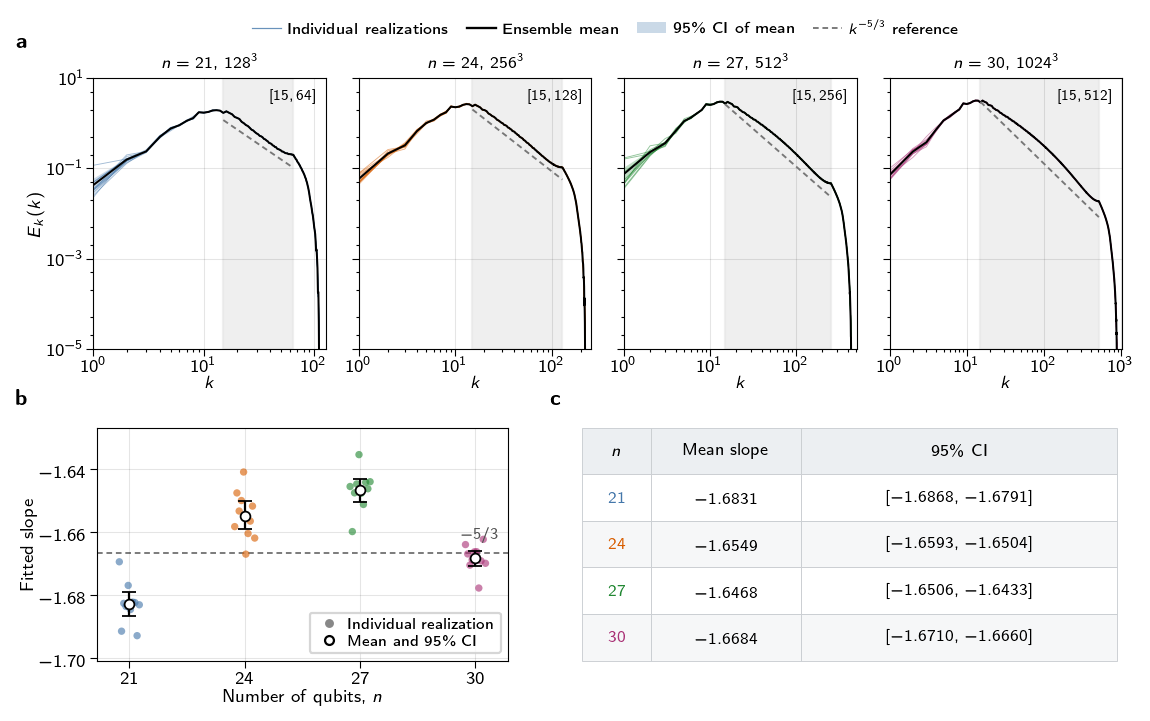

In [9]:
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for ax in axes:
    tight=ax.get_tightbbox(renderer)
    assert tight.x0>=0 and tight.y0>=0, (tight.x0,tight.y0)
    assert tight.x1<=fig.bbox.width and tight.y1<=fig.bbox.height
dimensions = {
    "canvas_width_cm": float(fig.get_figwidth()*2.54),
    "canvas_height_cm": float(fig.get_figheight()*2.54),
    "style":str(style_path),
    "line_panels":[],
}
for label,ax in zip(["a: n=21","a: n=24","a: n=27","a: n=30","b"],axes[:5]):
    box=ax.get_position()
    width=box.width*fig.get_figwidth()*2.54
    height=box.height*fig.get_figheight()*2.54
    dimensions["line_panels"].append({"panel":label,"width_cm":float(width),
        "height_cm":float(height),"width_height_ratio":float(width/height)})
dimensions["groups"]={"a":"four original spectrum axes in one row",
                       "b":"phase-realization slopes","c":"numerical summary"}
dimensions["spectrum_display_range"]="1 <= k <= N, including full positive-power tails"
dimensions["spectrum_y_limits"]=list(SPECTRUM_YLIM)
assert abs(dimensions["canvas_width_cm"]-FIG_WIDTH_CM)<1e-10
(OUT/"figure_dimensions.json").write_text(json.dumps(dimensions,indent=2),encoding="utf-8")
fig.savefig(OUT/"velocity_spectrum_robustness.pdf",dpi=600)
fig.savefig(OUT/"velocity_spectrum_robustness.png",dpi=450)
fig.savefig(OUT/"velocity_spectrum_robustness_preview.png",dpi=170)
display(fig)
plt.close(fig)
print("Saved figure to",OUT)
